# X5 RetailHero: customer history to a targeting decision

Run `uv run python run_x5.py` first. This walkthrough reads the locked analysis; it does not tune on test. Assignment is assumed random at p=0.5; the public documentation does not establish the full assignment protocol.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if Path("run_x5.py").exists() else Path.cwd().parent
OUT = ROOT / "reports/x5"
summary = json.loads((OUT / "summary.json").read_text())
summary["quality"]

{'receipt_count': 4024949,
 'history_start': '2018-11-21 21:02:33',
 'eligible_item_lines': 22882690,
 'history_end': '2019-03-18 23:19:28',
 'feature_reference_date': '2019-03-19 00:00:00',
 'reference_note': 'Day after latest provided pre-communication receipt; not the campaign date or an observed outcome-window boundary.',
 'cache_key': {'schema_version': 2,
  'sources': {'uplift_train.csv.gz': {'url': 'https://sklift.s3.eu-west-2.amazonaws.com/uplift_train.csv.gz',
    'sha256': '0a218e864a1ec1dfe26e980a082b81d5f46d199c4a6ae32abbaa95265af1c2c7',
    'bytes': 1182423},
   'clients.csv.gz': {'url': 'https://sklift.s3.eu-west-2.amazonaws.com/clients.csv.gz',
    'sha256': 'bfca1719b862735ae9816ed9bbba6924931c6a4dff761c481efe9addff458429',
    'bytes': 7637755},
   'purchases.csv.gz': {'url': 'https://sklift.s3.eu-west-2.amazonaws.com/purchases.csv.gz',
    'sha256': '3d57519fa92b553fd1e947c120add475cc42e0c64c323a52cef5aebe8645c8e2',
    'bytes': 669979268}}},
 'source_hashes': {'uplif

## Local customer features

The raw profiles and purchase history stay in `data/x5/`. `customer_features.parquet` contains client ID and 16 model features, with no assignment or outcome columns. This notebook shows its schema and aggregate counts only. Repeated receipt totals are counted once, before customer aggregation.

In [2]:
import duckdb

feature_path = str(ROOT / "data/x5/customer_features.parquet")
con = duckdb.connect()
display(
    con.execute("DESCRIBE SELECT * FROM read_parquet(?)", [feature_path]).df()[
        ["column_name", "column_type"]
    ]
)
print(
    "Customer rows:",
    con.execute("SELECT count(*) FROM read_parquet(?)", [feature_path]).fetchone()[0],
)
con.close()

,column_name,column_type
0,client_id,VARCHAR
1,age,BIGINT
2,transactions,BIGINT
3,total_spend,DOUBLE
4,mean_basket,DOUBLE
5,recency_days,BIGINT
6,active_days,BIGINT
7,history_days,BIGINT
8,transactions_30d,BIGINT
9,spend_30d,DOUBLE


Customer rows: 200039


## Allocation, balance and average difference

These diagnostics can reveal problems; they cannot prove random assignment.

counts     {'0': 100058, '1': 99981}
p_value                     0.863311
dtype: object

control_rate           0.603280
treatment_rate         0.636511
ate                    0.033231
ci_low                 0.028979
ci_high                0.037483
n_control         100058.000000
n_treatment        99981.000000
dtype: float64

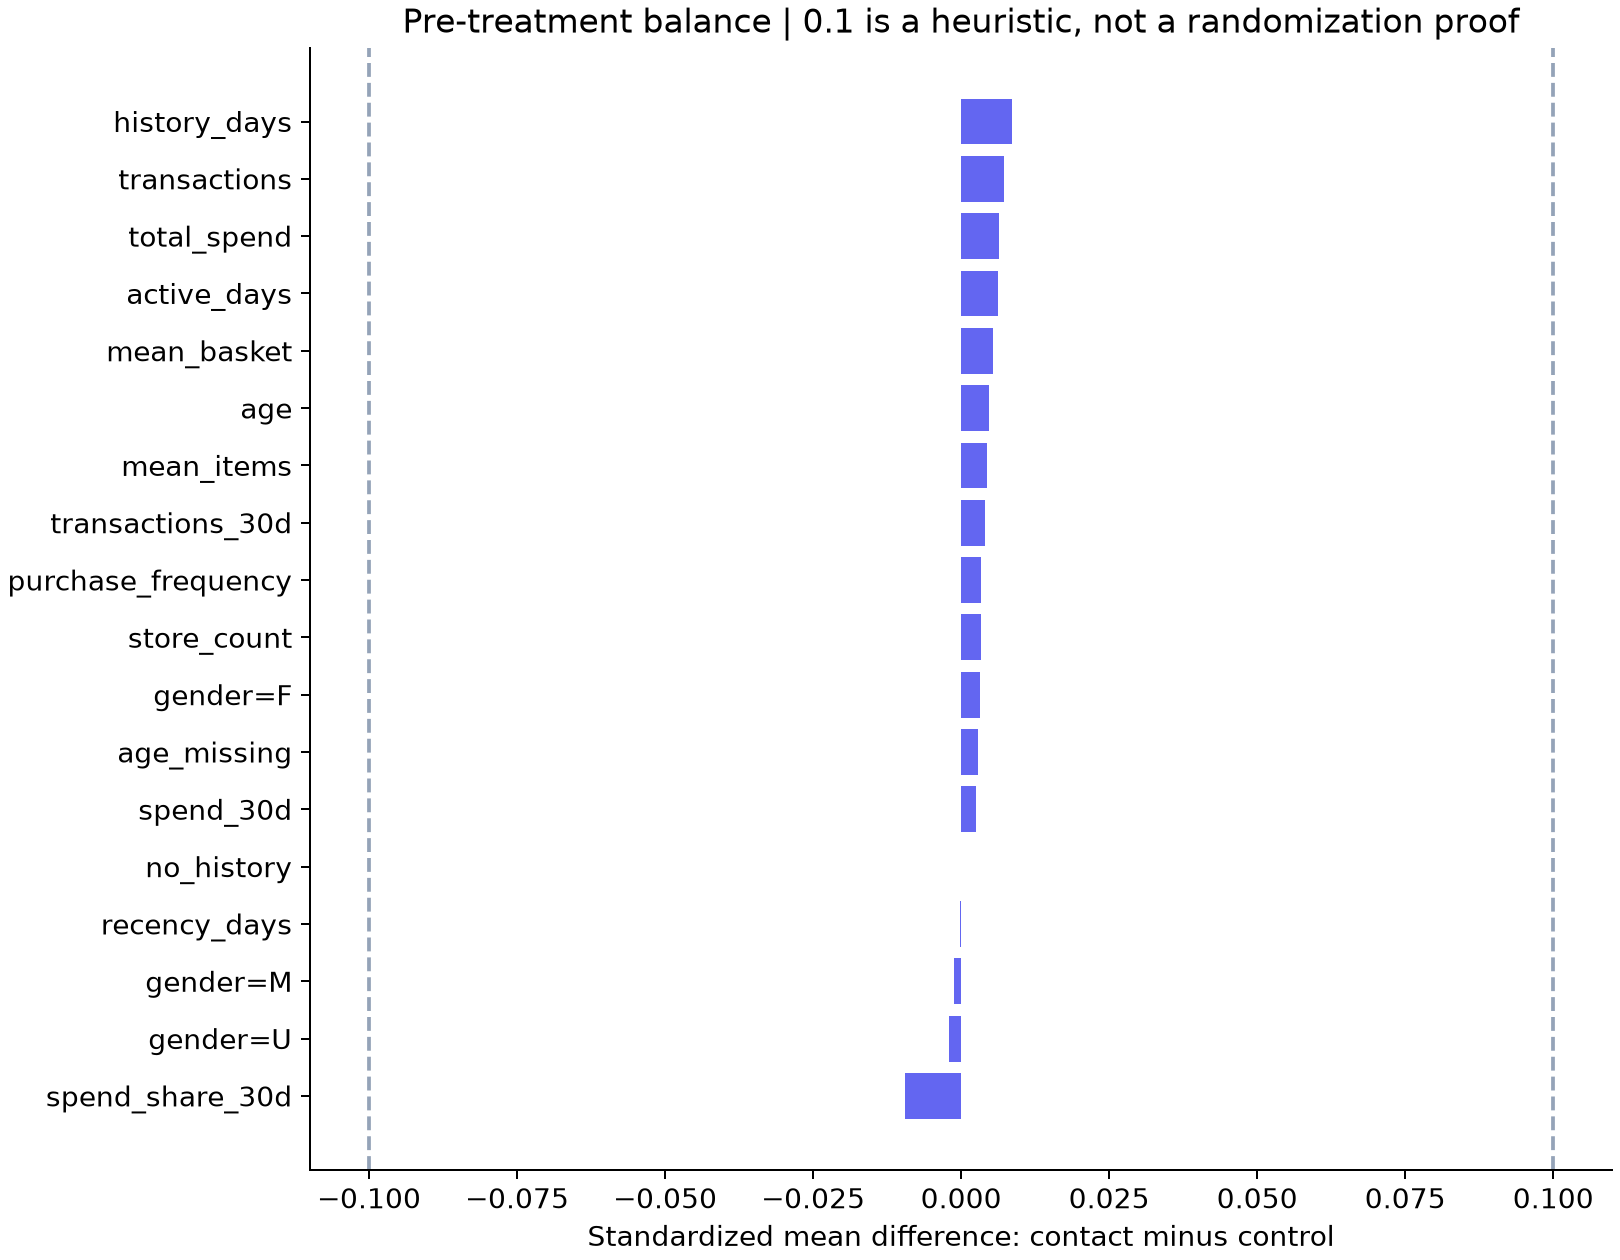

In [3]:
display(pd.Series(summary["allocation"]))
display(pd.Series(summary["purchase_difference"]))
display(Image(filename=str(OUT / "figures/balance.png")))

## Locked decision and held-out ranking

Train/validation/test are separate customers. Models and RFM reference fit train; policy and reach are selected on validation. Test comparisons are diagnostics, not permission to choose another winner.

policy                                      all
fraction                                    1.0
net_per_customer                        1.79924
ci_low                                 0.253531
ci_high                                 3.34495
net_per_1000                        1799.240152
coverage                                    1.0
incremental_conversions_per_1000      37.992402
dtype: object

,model,qini_auc_normalized,auuc_normalized,uplift_at_20pct
0,s_learner,0.010022,0.015820,0.058940
1,t_learner,0.006642,0.010633,0.065541
2,response_baseline,-0.008575,-0.013371,0.005770
3,rfm_baseline,-0.009435,-0.014766,0.012082


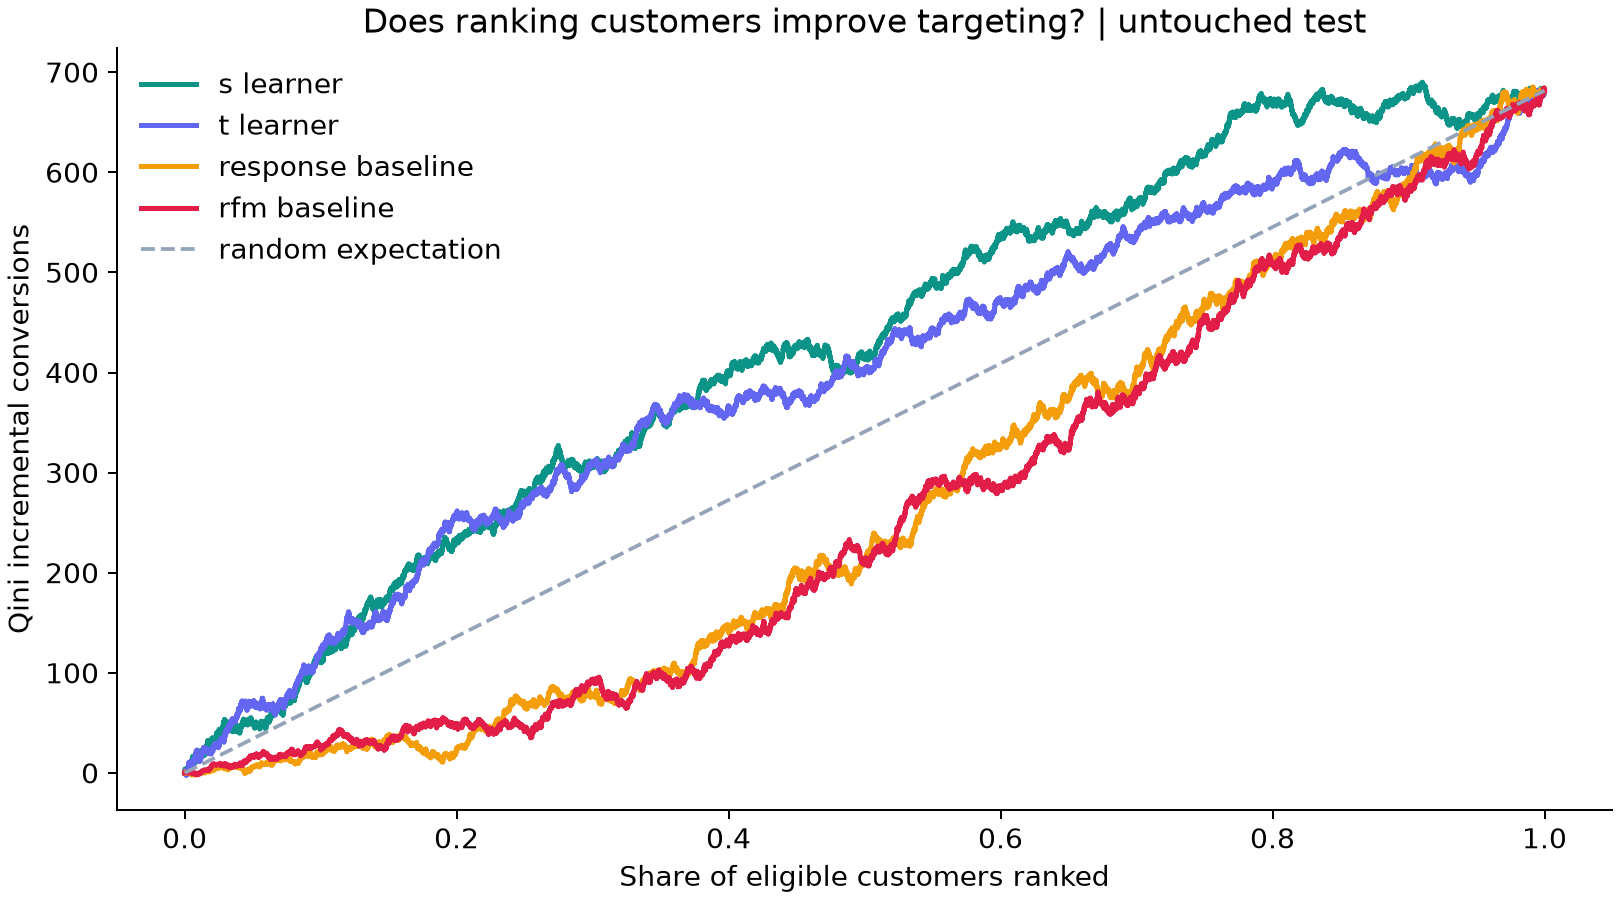

In [4]:
display(pd.Series(summary["selected_on_validation"]))
display(pd.read_csv(OUT / "ranking_metrics.csv"))
display(Image(filename=str(OUT / "figures/qini.png")))

## Economics and uncertainty

100 RUB contribution per incremental purchase and 2 RUB contact cost are scenario inputs. Policy value uses observed held-out assignment/outcomes, not a sum of uplift predictions. Confidence intervals condition on fitted models and masks; they omit training and threshold uncertainty.

,label,net_per_customer,ci_low,ci_high,net_per_1000,coverage,incremental_conversions_per_1000
0,no contact,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,contact all,1.359328,-0.184180,2.902836,1359.328134,1.000000,33.593281
2,random same coverage,1.359328,-0.184180,2.902836,1359.328134,1.000000,33.593281
3,RFM same coverage,1.359328,-0.184180,2.902836,1359.328134,1.000000,33.593281
4,selected: all,1.359328,-0.184180,2.902836,1359.328134,1.000000,33.593281
5,random at 20%,0.564837,-0.123650,1.253324,564.837033,0.199985,9.648070
6,s_learner at 20%,0.469856,-0.122505,1.062217,469.856029,0.199985,8.698260
7,t_learner at 20%,0.584833,-0.019117,1.188783,584.833033,0.199985,9.848030
8,response_baseline at 20%,-0.215007,-1.059171,0.629157,-215.006999,0.199985,1.849630
9,rfm_baseline at 20%,-0.190012,-1.023815,0.643791,-190.011998,0.199985,2.099580


,net_per_customer,ci_low,ci_high,net_per_1000
no contact,1.359328,-0.18418,2.902836,1359.328134
contact all,0.000000,0.00000,0.000000,0.000000
random same coverage,0.000000,0.00000,0.000000,0.000000
RFM same coverage,0.000000,0.00000,0.000000,0.000000


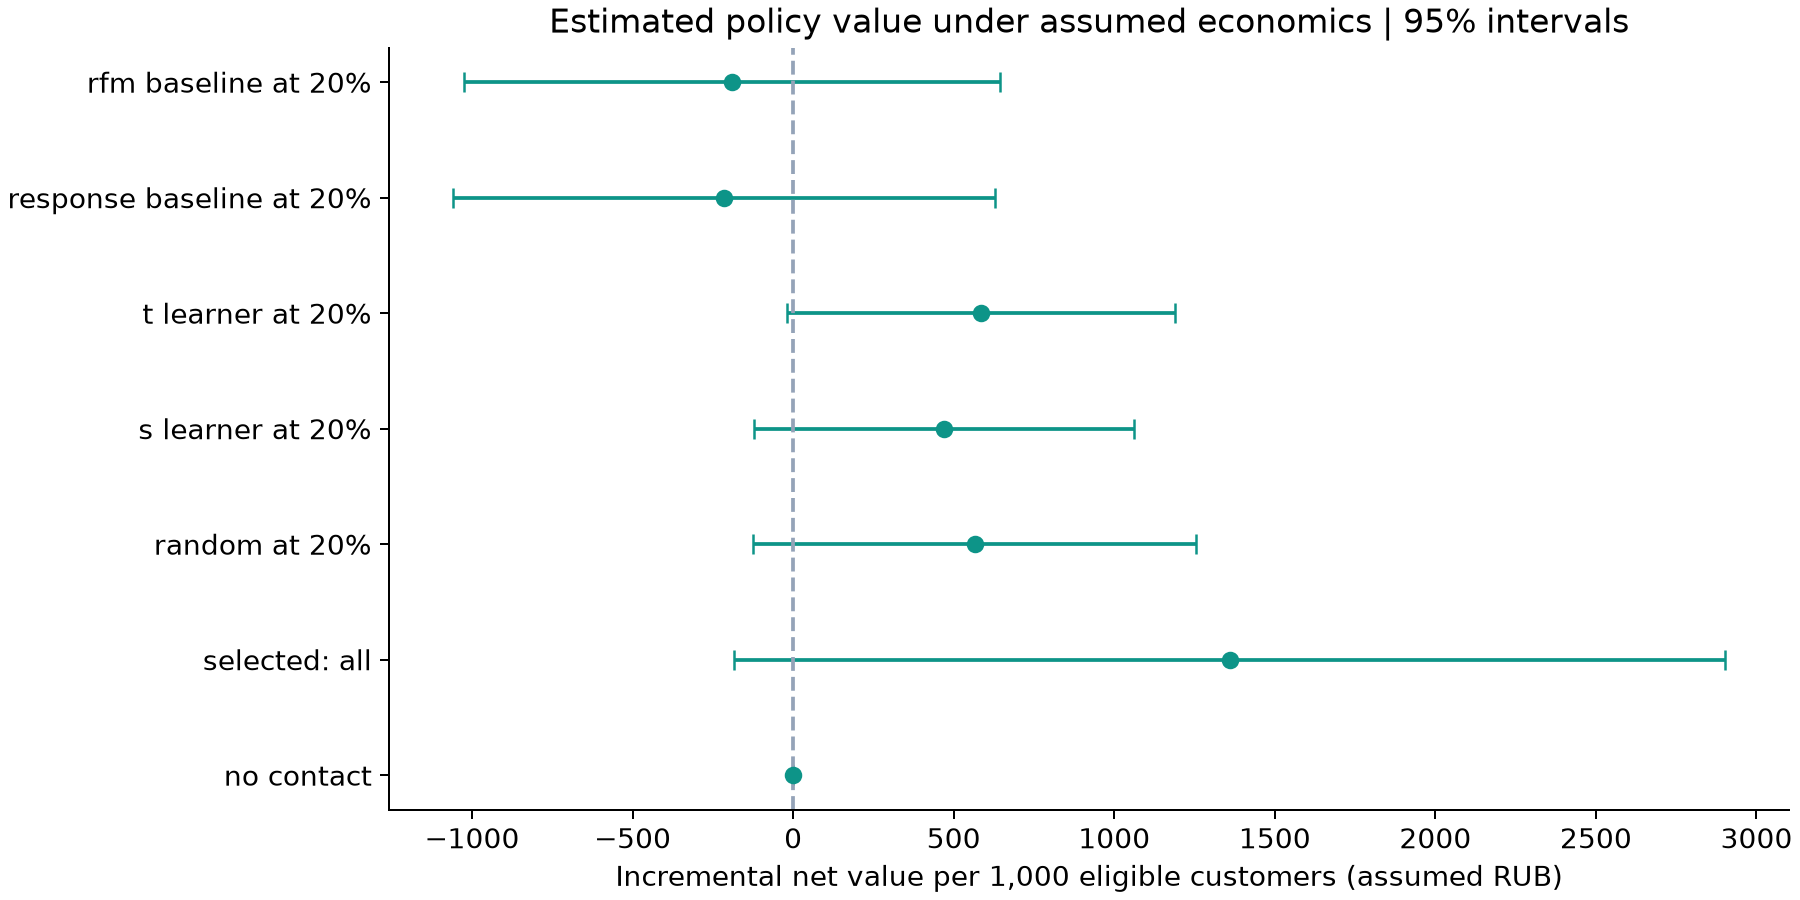

In [5]:
display(pd.read_csv(OUT / "policies_test.csv"))
display(pd.DataFrame(summary["paired_test_comparisons"]).T)
display(Image(filename=str(OUT / "figures/policy_value.png")))

## Interview discussion

Why can purchase propensity outperform uplift ranking? How much evidence supports the locked rule versus RFM at the same reach? Which source assumptions must be confirmed before deployment? What margin/contact guardrails belong in the next prospective randomized test?

Connect these decisions to your actual A/B and ML experience; the project does not invent professional outcomes.

## Economic decision maps

Policy and reach are selected on validation separately for each assumed contribution/contact-cost scenario. Test only evaluates those locked plans. This extension follows initial test inspection and is exploratory; pointwise intervals do not adjust for selection or multiple comparisons.

,value,cost,policy,fraction,validation_coverage,validation_net_per_1000,test_net_per_customer,test_ci_low,test_ci_high,test_net_per_1000,test_coverage,test_incremental_conversions_per_1000
0,25.0,0.0,all,1.0,1.000000,949.810038,0.839832,0.453955,1.225709,839.832034,1.000000,33.593281
1,25.0,0.5,all,1.0,1.000000,449.810038,0.339832,-0.046045,0.725709,339.832034,1.000000,33.593281
2,25.0,1.0,s_learner,0.3,0.299990,171.165767,-0.003799,-0.186058,0.178459,-3.799240,0.299990,11.847630
3,25.0,2.0,t_learner,0.1,0.099980,22.495501,-0.061238,-0.164711,0.042236,-61.237752,0.099980,5.548890
4,25.0,5.0,none,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5,25.0,10.0,none,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
6,50.0,0.0,all,1.0,1.000000,1899.620076,1.679664,0.907910,2.451418,1679.664067,1.000000,33.593281
7,50.0,0.5,all,1.0,1.000000,1399.620076,1.179664,0.407910,1.951418,1179.664067,1.000000,33.593281
8,50.0,1.0,all,1.0,1.000000,899.620076,0.679664,-0.092090,1.451418,679.664067,1.000000,33.593281
9,50.0,2.0,s_learner,0.3,0.299990,342.331534,-0.007598,-0.372115,0.356918,-7.598480,0.299990,11.847630


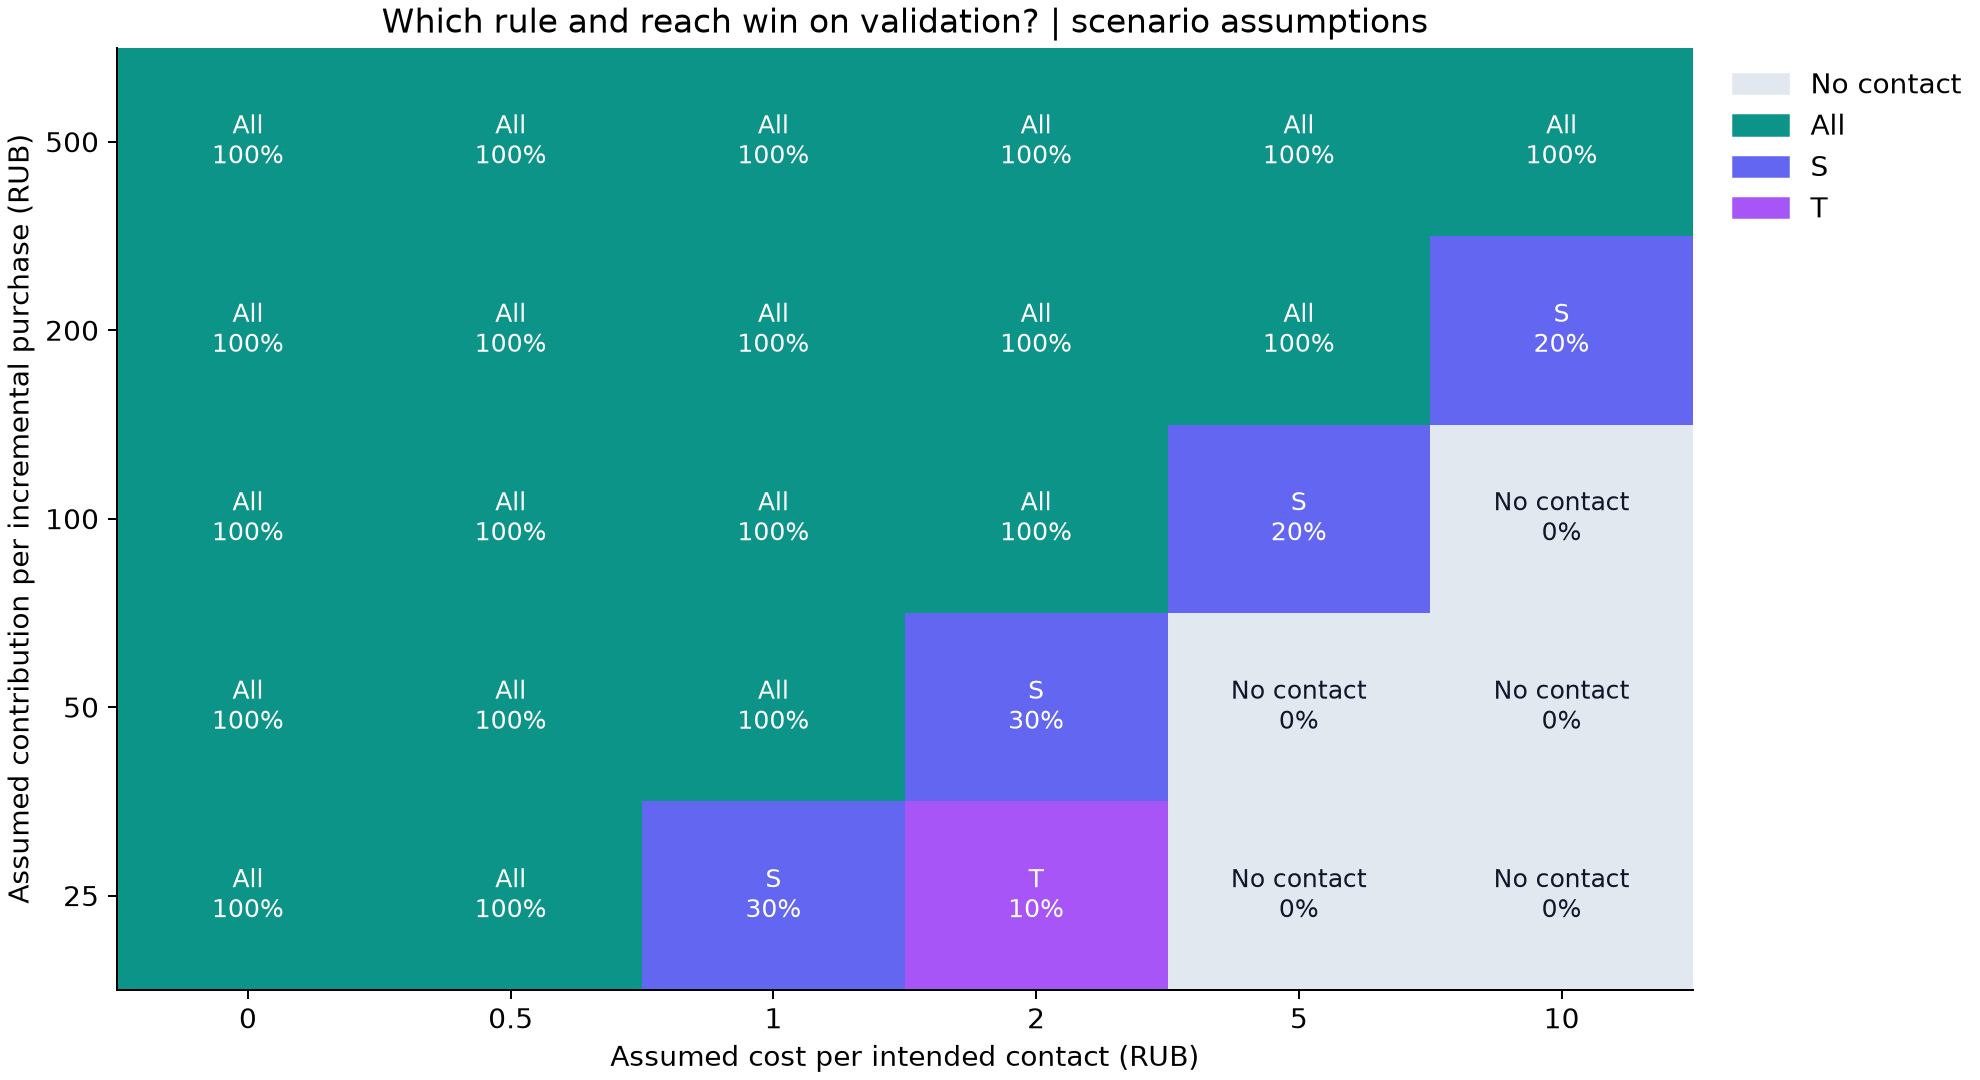

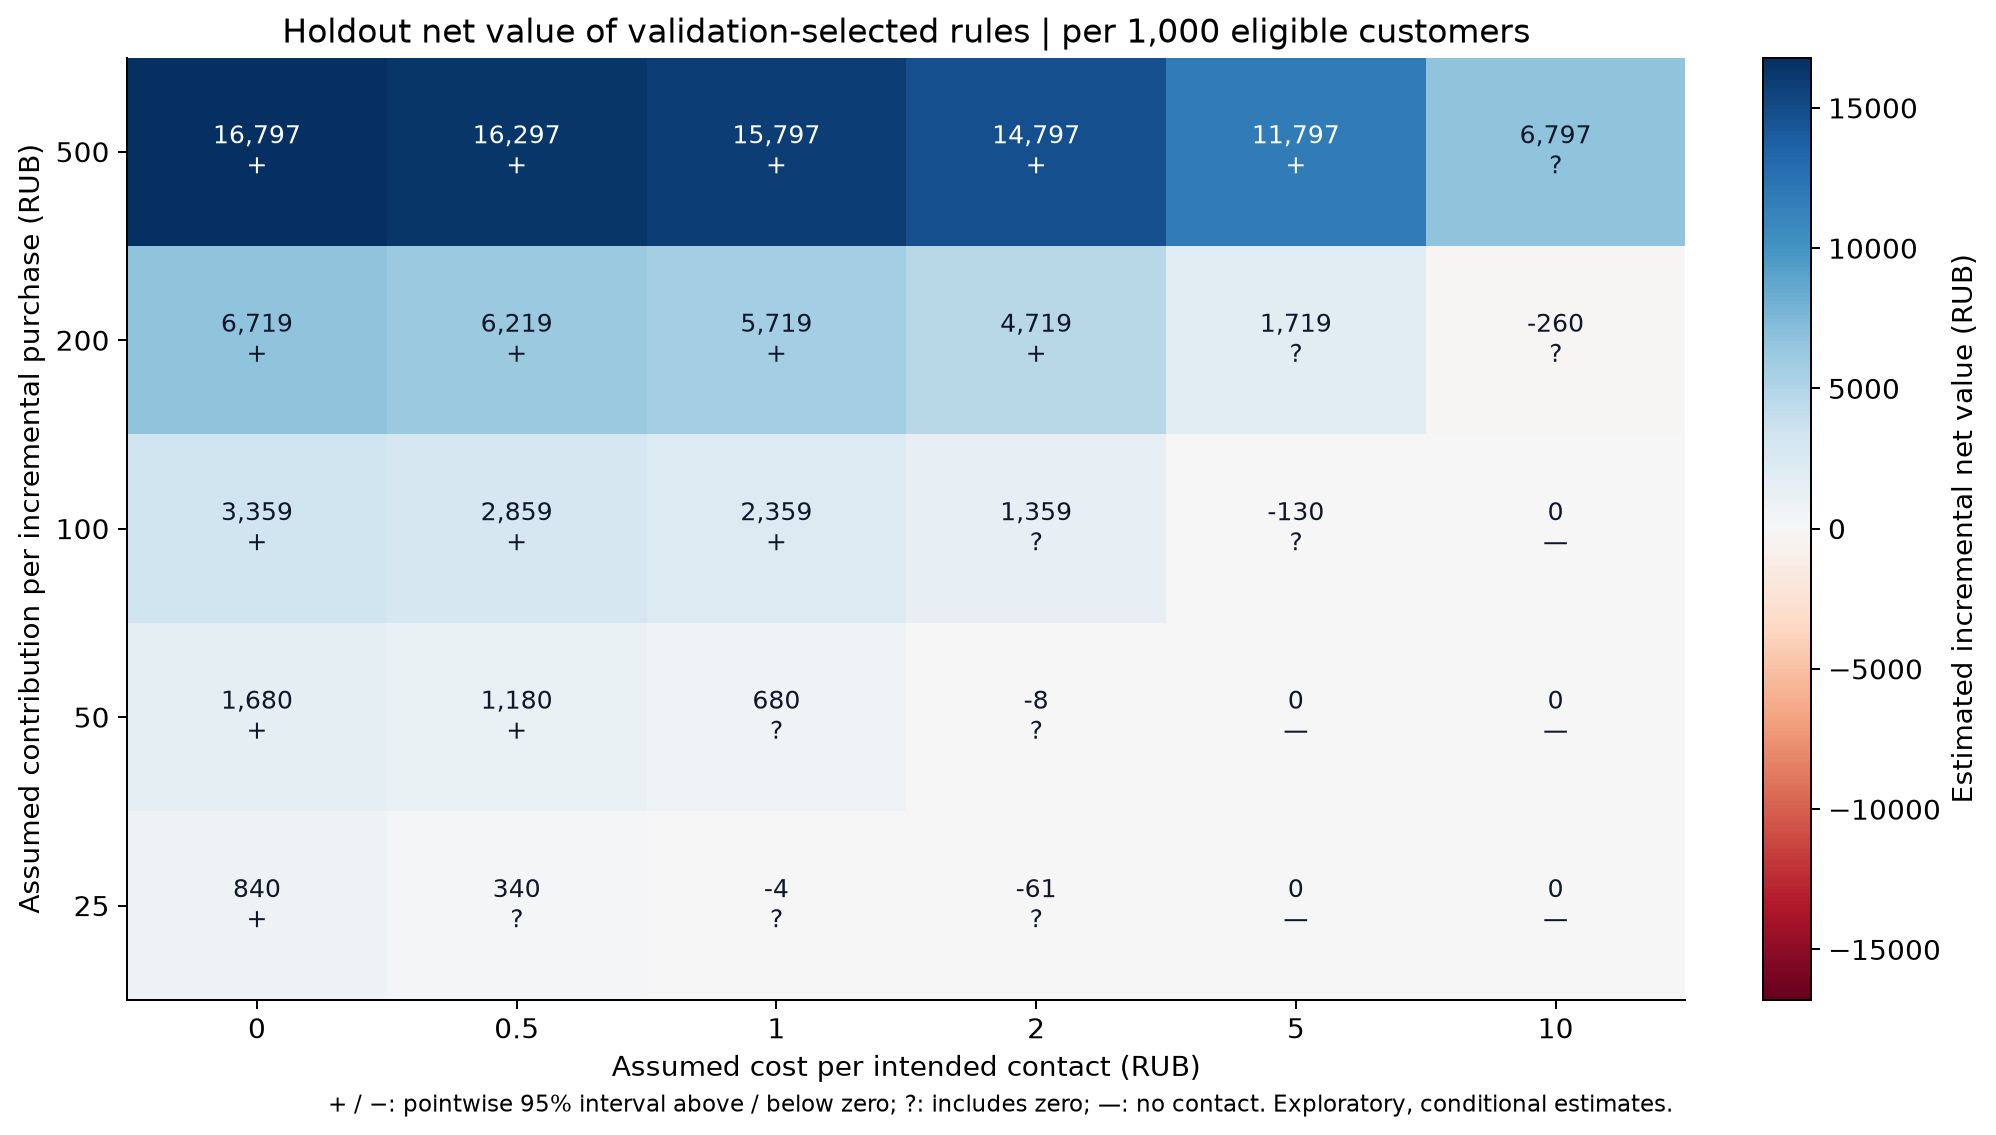

In [6]:
display(pd.read_csv(OUT / "economics_scenarios.csv"))
display(Image(filename=str(OUT / "figures/decision_map.png")))
display(Image(filename=str(OUT / "figures/scenario_value.png")))